# Business Understanding

### Forecast macroeconomic indicators

## Initial Setups

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
#Read data from csv file
data = pd.read_csv('cs_11.csv')
data.head()

,date,sales
0,1976-Jan,885.2
1,1976-Feb,994.7
2,1976-Mar,1243.6
3,1976-Apr,1191.2
4,1976-May,1203.2


# Data Understanding

### 1: Understand data collection process

### US monthly total vehicle sales: 1976 - 2022.

### U.S. Bureau of Economic Analysis, Total Vehicle Sales, Federal Reserve Bank of St. Louis; https://fred.stlouisfed.org/series/TOTALNSA.

### 2: Document data set description (meta data)

In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 564 entries, 0 to 563
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   date    564 non-null    object 
 1   sales   564 non-null    float64
dtypes: float64(1), object(1)
memory usage: 8.9+ KB


#### 0 date: date (year-month)

#### 1 sales: sales volume in thousands of units

### 3: Check for missing values

In [4]:
np.sum(data.isnull(), axis = 0)

date     0
sales    0
dtype: int64

### 4: Univariate data analysis

In [5]:
#Extract year and month from date
data['year'] = data['date'].apply(lambda s: s.split('-')[0]).astype(int)
data['month'] = data['date'].apply(lambda s: s.split('-')[1])
data.head()

,date,sales,year,month
0,1976-Jan,885.2,1976,Jan
1,1976-Feb,994.7,1976,Feb
2,1976-Mar,1243.6,1976,Mar
3,1976-Apr,1191.2,1976,Apr
4,1976-May,1203.2,1976,May


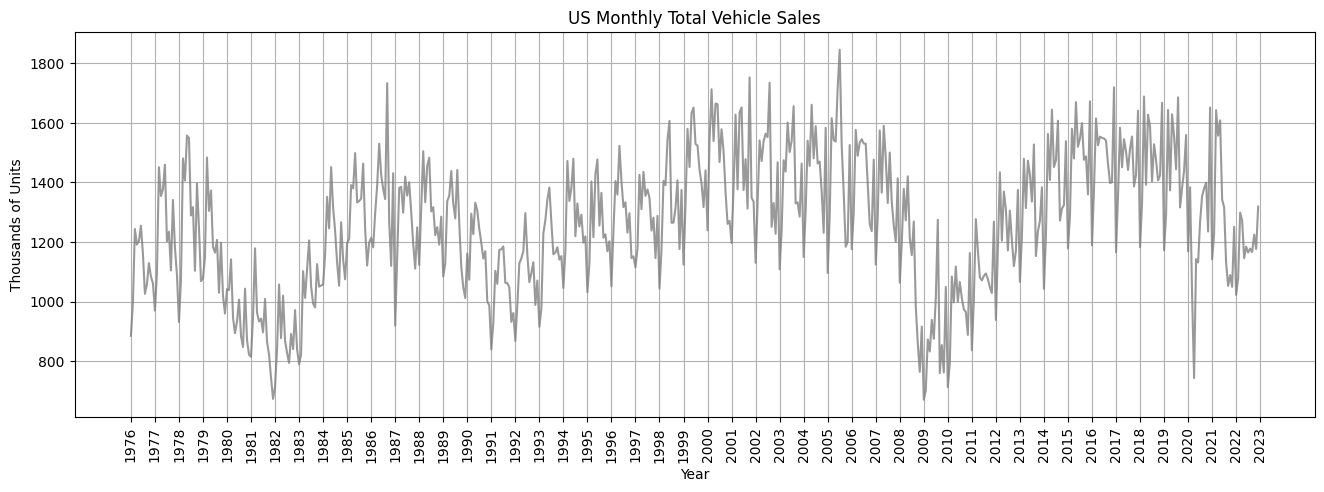

In [6]:
#Line chart
plt.figure(figsize = (16, 5))
plt.plot(data['date'], data['sales'], 
         color = 'grey', alpha = 0.8)
plt.title('US Monthly Total Vehicle Sales')
plt.xlabel('Year')
plt.ylabel('Thousands of Units')
plt.xticks(ticks = range(0, data.shape[0] + 1, 12) , 
           labels = range(1976, 2024), 
           rotation = 90)
plt.grid()
plt.show()

In [8]:
%pip install statsmodels

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 3.1 MB/s  0:00:03 3.0 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [statsmodels] 1/2 [statsmodels]
Note: you may need to restart the kernel to use updated packages.


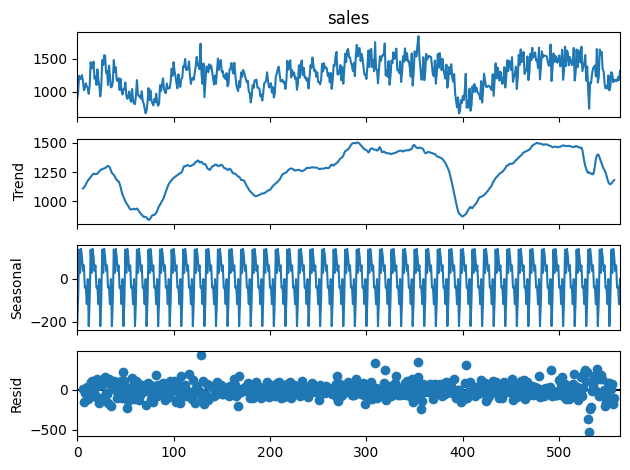

In [9]:
#Time series decomposition
from statsmodels.tsa.seasonal import seasonal_decompose

#Additive decomposition
add_decompose = seasonal_decompose(data['sales'], 
                                   model = 'additive', #additive vs. multiplicative
                                   period = 12, #Period of the series
                                   two_sided = True) #centered moving average is computed

#Plot the results
add_decompose.plot()
plt.show()

In [10]:
#Detrend time series (optional)
data['detrend_sales'] = data['sales'] - add_decompose.trend
data.head(20)

,date,sales,year,month,detrend_sales
0,1976-Jan,885.2,1976,Jan,NaN
1,1976-Feb,994.7,1976,Feb,NaN
2,1976-Mar,1243.6,1976,Mar,NaN
3,1976-Apr,1191.2,1976,Apr,NaN
4,1976-May,1203.2,1976,May,NaN
5,1976-Jun,1254.7,1976,Jun,NaN
6,1976-Jul,1162.3,1976,Jul,50.895833
7,1976-Aug,1026.1,1976,Aug,-92.891667
8,1976-Sep,1057.9,1976,Sep,-73.795833
9,1976-Oct,1129.4,1976,Oct,-17.741667


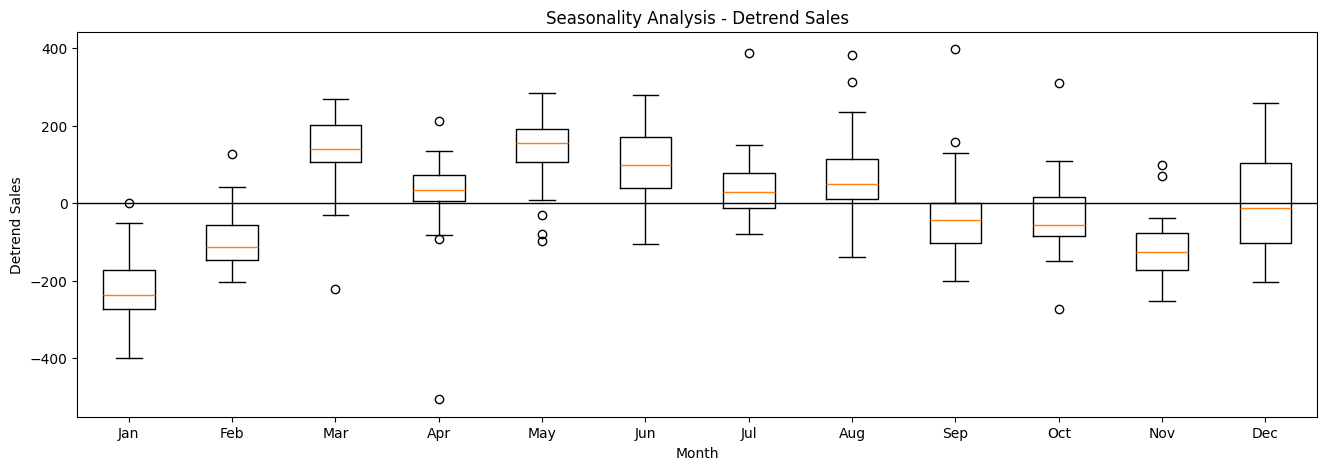

In [11]:
#Seasonality analysis
#Boxplot of detrend sales vs. month
plt.figure(figsize = (16, 5))
plt.boxplot([data.loc[(data['month'] == _) &
                      (data['detrend_sales'].notnull()), 
                      'detrend_sales'] for _ in data['month'].unique()])
plt.title('Seasonality Analysis - Detrend Sales')
plt.axhline(y = 0, color = 'black', linewidth = 1)
plt.xticks(ticks = range(1, 13), labels = data['month'].unique())
plt.xlabel('Month')
plt.ylabel('Detrend Sales')
plt.show()

In [12]:
#Calculate ACF and PACF up to 36 lags
from statsmodels.tsa.stattools import acf, pacf
acf_36 = acf(data['sales'], nlags = 36)
pacf_36 = pacf(data['sales'], nlags = 36)
print(acf_36)
print(pacf_36)

[1.         0.69920612 0.64012355 0.61140411 0.48287135 0.46187505
 0.40498805 0.43649182 0.43480537 0.53952859 0.52825964 0.55792522
 0.74348114 0.51938    0.50376186 0.46352882 0.34601172 0.3279812
 0.262121   0.28988746 0.29023502 0.36841956 0.36297638 0.39825358
 0.53824344 0.3456746  0.31868045 0.26561919 0.16788474 0.1366069
 0.06510849 0.09438454 0.09540225 0.17208269 0.18279298 0.20639181
 0.3440322 ]
[ 1.          0.70044805  0.29796286  0.19405655 -0.10395793  0.06090807
 -0.00822817  0.2041311   0.0791185   0.33978017  0.00337139  0.15044647
  0.46617941 -0.4198549  -0.04989283 -0.10564037 -0.08512077 -0.0394317
 -0.08546055  0.01539329  0.01736607 -0.03953629  0.06535241  0.03959857
  0.09324442 -0.13570684 -0.17243381 -0.06137855 -0.01305742 -0.09034194
 -0.04620482 -0.01602682  0.00243076  0.04892345  0.06542211 -0.02554553
  0.16780402]


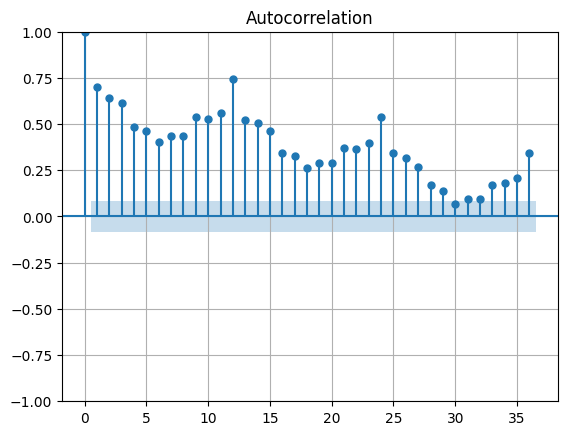

In [13]:
#Plot ACF up to 36 lags
from statsmodels.graphics.tsaplots import plot_acf
plot_acf(data['sales'], lags = 36, bartlett_confint = False)
plt.grid()
plt.show()

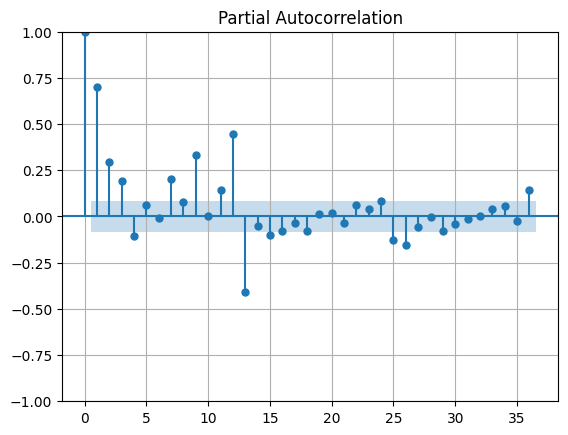

In [14]:
#Plot PACF up to 36 lags
from statsmodels.graphics.tsaplots import plot_pacf
plot_pacf(data['sales'], lags = 36, method = 'ywm')
plt.grid()
plt.show()

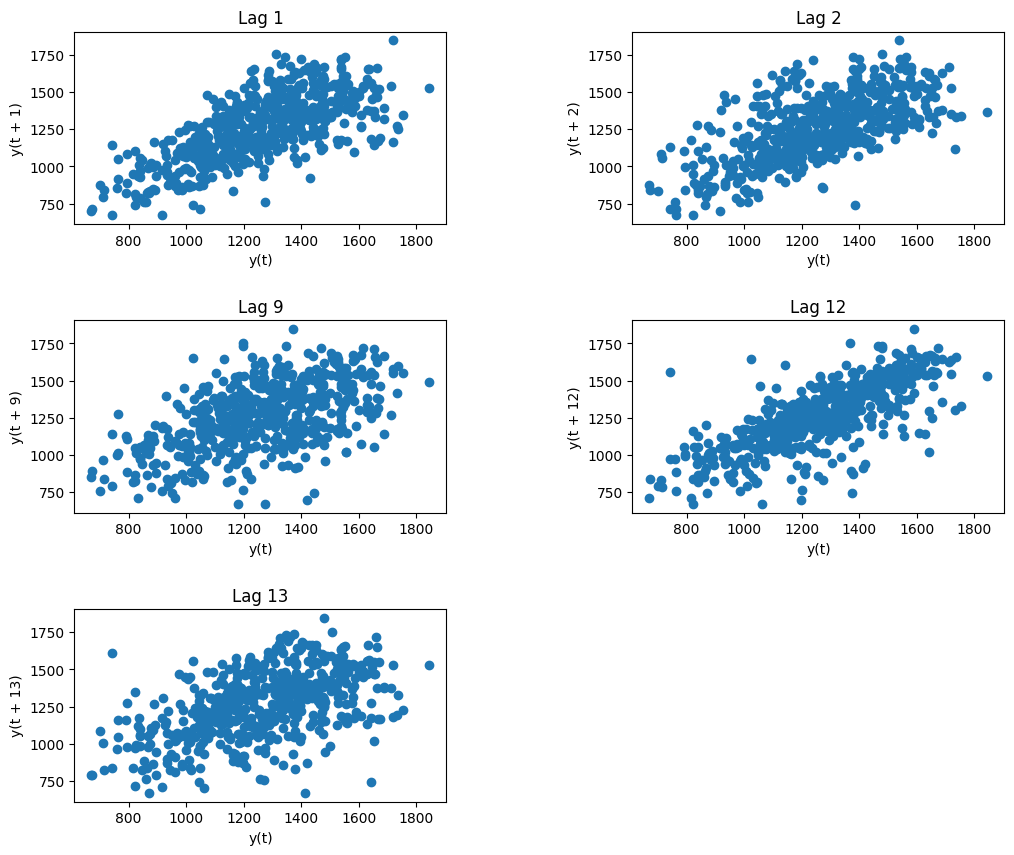

In [15]:
#Scatter plot of lags (abs(auto-correlation) >= 0.25)
lags = [1, 2, 9, 12, 13]
plt.figure(figsize = (12, 10))
plt.subplots_adjust(hspace = 0.5, wspace = 0.5)
for i in range(1, 6):
    plt.subplot(3, 2, i)
    pd.plotting.lag_plot(data['sales'], lag = lags[i - 1])
    plt.title('Lag ' + str(lags[i - 1]))

## Data Preparation

In [16]:
data.shape

(564, 5)

In [17]:
#Add series trend
data['trend'] = np.arange(1, data.shape[0] + 1)
data.head()

,date,sales,year,month,detrend_sales,trend
0,1976-Jan,885.2,1976,Jan,NaN,1
1,1976-Feb,994.7,1976,Feb,NaN,2
2,1976-Mar,1243.6,1976,Mar,NaN,3
3,1976-Apr,1191.2,1976,Apr,NaN,4
4,1976-May,1203.2,1976,May,NaN,5


In [18]:
#Define dummy variables for month
dummy_vars = pd.get_dummies(data['month']).reindex(columns = data['month'].unique())
dummy_vars.drop(columns = 'Jan', inplace = True)
dummy_vars.head()

,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
0,False,False,False,False,False,False,False,False,False,False,False
1,True,False,False,False,False,False,False,False,False,False,False
2,False,True,False,False,False,False,False,False,False,False,False
3,False,False,True,False,False,False,False,False,False,False,False
4,False,False,False,True,False,False,False,False,False,False,False


In [19]:
#Lower case column names 
dummy_vars.columns = [_.lower() for _ in dummy_vars.columns]
dummy_vars.head()

,feb,mar,apr,may,jun,jul,aug,sep,oct,nov,dec
0,False,False,False,False,False,False,False,False,False,False,False
1,True,False,False,False,False,False,False,False,False,False,False
2,False,True,False,False,False,False,False,False,False,False,False
3,False,False,True,False,False,False,False,False,False,False,False
4,False,False,False,True,False,False,False,False,False,False,False


In [20]:
#Add dummy variables for seasonal component
data = pd.concat([data, dummy_vars], axis = 1)
data.head()

,date,sales,year,month,detrend_sales,trend,feb,mar,apr,may,jun,jul,aug,sep,oct,nov,dec
0,1976-Jan,885.2,1976,Jan,NaN,1,False,False,False,False,False,False,False,False,False,False,False
1,1976-Feb,994.7,1976,Feb,NaN,2,True,False,False,False,False,False,False,False,False,False,False
2,1976-Mar,1243.6,1976,Mar,NaN,3,False,True,False,False,False,False,False,False,False,False,False
3,1976-Apr,1191.2,1976,Apr,NaN,4,False,False,True,False,False,False,False,False,False,False,False
4,1976-May,1203.2,1976,May,NaN,5,False,False,False,True,False,False,False,False,False,False,False


In [21]:
#Add lags of sales as features
lags = [1, 2, 9, 12, 13]
for i in range(len(lags)):
    data['lag_' + str(lags[i])] = data['sales'].shift(lags[i])
data.head()

,date,sales,year,month,detrend_sales,trend,feb,mar,apr,may,...,aug,sep,oct,nov,dec,lag_1,lag_2,lag_9,lag_12,lag_13
0,1976-Jan,885.2,1976,Jan,NaN,1,False,False,False,False,...,False,False,False,False,False,NaN,NaN,NaN,NaN,NaN
1,1976-Feb,994.7,1976,Feb,NaN,2,True,False,False,False,...,False,False,False,False,False,885.2,NaN,NaN,NaN,NaN
2,1976-Mar,1243.6,1976,Mar,NaN,3,False,True,False,False,...,False,False,False,False,False,994.7,885.2,NaN,NaN,NaN
3,1976-Apr,1191.2,1976,Apr,NaN,4,False,False,True,False,...,False,False,False,False,False,1243.6,994.7,NaN,NaN,NaN
4,1976-May,1203.2,1976,May,NaN,5,False,False,False,True,...,False,False,False,False,False,1191.2,1243.6,NaN,NaN,NaN


In [22]:
#Drop detrend_sales columns
data.drop(columns = 'detrend_sales', inplace = True)

In [23]:
#Drop rows with missing values
data.dropna(axis = 0, inplace = True)

In [24]:
data.head()

,date,sales,year,month,trend,feb,mar,apr,may,jun,...,aug,sep,oct,nov,dec,lag_1,lag_2,lag_9,lag_12,lag_13
13,1977-Feb,1092.1,1977,Feb,14,True,False,False,False,False,...,False,False,False,False,False,969.9,1061.8,1203.2,994.7,885.2
14,1977-Mar,1451.1,1977,Mar,15,False,True,False,False,False,...,False,False,False,False,False,1092.1,969.9,1254.7,1243.6,994.7
15,1977-Apr,1354.4,1977,Apr,16,False,False,True,False,False,...,False,False,False,False,False,1451.1,1092.1,1162.3,1191.2,1243.6
16,1977-May,1377.1,1977,May,17,False,False,False,True,False,...,False,False,False,False,False,1354.4,1451.1,1026.1,1203.2,1191.2
17,1977-Jun,1459.8,1977,Jun,18,False,False,False,False,True,...,False,False,False,False,False,1377.1,1354.4,1057.9,1254.7,1203.2


In [25]:
data.tail()

,date,sales,year,month,trend,feb,mar,apr,may,jun,...,aug,sep,oct,nov,dec,lag_1,lag_2,lag_9,lag_12,lag_13
559,2022-Aug,1178.066,2022,Aug,560,False,False,False,False,False,...,True,False,False,False,False,1164.691,1184.437,1049.604,1128.965,1316.697
560,2022-Sep,1166.015,2022,Sep,561,False,False,False,False,False,...,False,True,False,False,False,1178.066,1164.691,1250.985,1052.965,1128.965
561,2022-Oct,1224.679,2022,Oct,562,False,False,False,False,False,...,False,False,True,False,False,1166.015,1178.066,1022.334,1089.348,1052.965
562,2022-Nov,1176.556,2022,Nov,563,False,False,False,False,False,...,False,False,False,True,False,1224.679,1166.015,1077.869,1049.604,1089.348
563,2022-Dec,1319.001,2022,Dec,564,False,False,False,False,False,...,False,False,False,False,True,1176.556,1224.679,1299.165,1250.985,1049.604


In [26]:
#Reset index
data.index = range(data.shape[0])
data

,date,sales,year,month,trend,feb,mar,apr,may,jun,...,aug,sep,oct,nov,dec,lag_1,lag_2,lag_9,lag_12,lag_13
0,1977-Feb,1092.100,1977,Feb,14,True,False,False,False,False,...,False,False,False,False,False,969.900,1061.800,1203.200,994.700,885.200
1,1977-Mar,1451.100,1977,Mar,15,False,True,False,False,False,...,False,False,False,False,False,1092.100,969.900,1254.700,1243.600,994.700
2,1977-Apr,1354.400,1977,Apr,16,False,False,True,False,False,...,False,False,False,False,False,1451.100,1092.100,1162.300,1191.200,1243.600
3,1977-May,1377.100,1977,May,17,False,False,False,True,False,...,False,False,False,False,False,1354.400,1451.100,1026.100,1203.200,1191.200
4,1977-Jun,1459.800,1977,Jun,18,False,False,False,False,True,...,False,False,False,False,False,1377.100,1354.400,1057.900,1254.700,1203.200
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
546,2022-Aug,1178.066,2022,Aug,560,False,False,False,False,False,...,True,False,False,False,False,1164.691,1184.437,1049.604,1128.965,1316.697
547,2022-Sep,1166.015,2022,Sep,561,False,False,False,False,False,...,False,True,False,False,False,1178.066,1164.691,1250.985,1052.965,1128.965
548,2022-Oct,1224.679,2022,Oct,562,False,False,False,False,False,...,False,False,True,False,False,1166.015,1178.066,1022.334,1089.348,1052.965
549,2022-Nov,1176.556,2022,Nov,563,False,False,False,False,False,...,False,False,False,True,False,1224.679,1166.015,1077.869,1049.604,1089.348


## Build Forecasting Models

In [27]:
#Split data into test and train
forecast_horizon = 12
train = data.iloc[: -forecast_horizon, :]
test = data.iloc[-forecast_horizon : , :]

In [28]:
#Check train
train

,date,sales,year,month,trend,feb,mar,apr,may,jun,...,aug,sep,oct,nov,dec,lag_1,lag_2,lag_9,lag_12,lag_13
0,1977-Feb,1092.100,1977,Feb,14,True,False,False,False,False,...,False,False,False,False,False,969.900,1061.800,1203.200,994.700,885.200
1,1977-Mar,1451.100,1977,Mar,15,False,True,False,False,False,...,False,False,False,False,False,1092.100,969.900,1254.700,1243.600,994.700
2,1977-Apr,1354.400,1977,Apr,16,False,False,True,False,False,...,False,False,False,False,False,1451.100,1092.100,1162.300,1191.200,1243.600
3,1977-May,1377.100,1977,May,17,False,False,False,True,False,...,False,False,False,False,False,1354.400,1451.100,1026.100,1203.200,1191.200
4,1977-Jun,1459.800,1977,Jun,18,False,False,False,False,True,...,False,False,False,False,False,1377.100,1354.400,1057.900,1254.700,1203.200
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
534,2021-Aug,1128.965,2021,Aug,548,False,False,False,False,False,...,True,False,False,False,False,1316.697,1342.999,1235.258,1354.397,1268.455
535,2021-Sep,1052.965,2021,Sep,549,False,False,False,False,False,...,False,True,False,False,False,1128.965,1316.697,1651.406,1379.676,1354.397
536,2021-Oct,1089.348,2021,Oct,550,False,False,False,False,False,...,False,False,True,False,False,1052.965,1128.965,1141.709,1399.305,1379.676
537,2021-Nov,1049.604,2021,Nov,551,False,False,False,False,False,...,False,False,False,True,False,1089.348,1052.965,1226.714,1235.258,1399.305


In [29]:
#Check test 
test

,date,sales,year,month,trend,feb,mar,apr,may,jun,...,aug,sep,oct,nov,dec,lag_1,lag_2,lag_9,lag_12,lag_13
539,2022-Jan,1022.334,2022,Jan,553,False,False,False,False,False,...,False,False,False,False,False,1250.985,1049.604,1557.152,1141.709,1651.406
540,2022-Feb,1077.869,2022,Feb,554,True,False,False,False,False,...,False,False,False,False,False,1022.334,1250.985,1608.628,1226.714,1141.709
541,2022-Mar,1299.165,2022,Mar,555,False,True,False,False,False,...,False,False,False,False,False,1077.869,1022.334,1342.999,1642.749,1226.714
542,2022-Apr,1271.888,2022,Apr,556,False,False,True,False,False,...,False,False,False,False,False,1299.165,1077.869,1316.697,1557.152,1642.749
543,2022-May,1145.623,2022,May,557,False,False,False,True,False,...,False,False,False,False,False,1271.888,1299.165,1128.965,1608.628,1557.152
544,2022-Jun,1184.437,2022,Jun,558,False,False,False,False,True,...,False,False,False,False,False,1145.623,1271.888,1052.965,1342.999,1608.628
545,2022-Jul,1164.691,2022,Jul,559,False,False,False,False,False,...,False,False,False,False,False,1184.437,1145.623,1089.348,1316.697,1342.999
546,2022-Aug,1178.066,2022,Aug,560,False,False,False,False,False,...,True,False,False,False,False,1164.691,1184.437,1049.604,1128.965,1316.697
547,2022-Sep,1166.015,2022,Sep,561,False,False,False,False,False,...,False,True,False,False,False,1178.066,1164.691,1250.985,1052.965,1128.965
548,2022-Oct,1224.679,2022,Oct,562,False,False,False,False,False,...,False,False,True,False,False,1166.015,1178.066,1022.334,1089.348,1052.965


## Exponential Smoothing with Fixed Window

In [30]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
es = ExponentialSmoothing(train['sales'], 
                          trend = 'add', #'add', 'mul', or None
                          damped_trend = False, #    Should the trend component be damped
                          seasonal = 'add', #'add', 'mul', or None
                          seasonal_periods = 12, #The number of periods in a complete seasonal cycle
                          initialization_method = 'estimated', #Method for initialize the recursions
                          initial_level = None, #The initial level component
                          initial_trend = None, #The initial trend component
                          initial_seasonal = None) #The initial seasonal component
model_1 = es.fit()

In [31]:
#Model parameters
model_1.params

{'smoothing_level': 0.41727933994625,
 'smoothing_trend': 0.0,
 'smoothing_seasonal': 0.15660787403211945,
 'damping_trend': nan,
 'initial_level': 1227.333303852253,
 'initial_trend': -0.22613731844652457,
 'initial_seasons': array([-103.7320346 ,  183.12924036,   77.80506309,  145.93357645,
         132.11249333,    6.6715498 ,    9.31892913, -102.14219678,
          22.53706927,  -71.83077062, -126.34811453, -170.84851381]),
 'use_boxcox': False,
 'lamda': None,
 'remove_bias': False}

In [32]:
#Predict on test - model 1
pred_es_fw = model_1.forecast(steps = 12)
pred_es_fw

539     815.147140
540     969.125132
541    1198.569998
542    1046.160724
543    1243.525290
544    1161.190437
545    1151.696190
546    1215.539612
547    1100.902883
548    1081.339581
549    1033.284523
550    1263.268443
dtype: float64

In [33]:
#Absolute error
abs_err_es_fw = abs(test['sales'] - pred_es_fw)
abs_pct_err_es_fw = np.round(abs(test['sales'] - pred_es_fw) / test['sales'] * 100, 1)

#MAPE, MAE, and median, sd, IQR, max, min of absolute errors
from scipy.stats import iqr
models_comp = pd.DataFrame({'MAPE':                 abs_pct_err_es_fw.mean(),
                            'MAE':                  abs_err_es_fw.mean(),
                            'Median of AbsErrors' : abs_err_es_fw.median(),
                            'SD of AbsErrors' :     abs_err_es_fw.std(),
                            'IQR of AbsErrors':     iqr(abs_err_es_fw),
                            'Min of AbsErrors':     abs_err_es_fw.min(),
                            'Max of AbsErrors':     abs_err_es_fw.max()},
                           index = ['Exponential Smoothing - Fixed Window'])
models_comp

,MAPE,MAE,Median of AbsErrors,SD of AbsErrors,IQR of AbsErrors,Min of AbsErrors,Max of AbsErrors
Exponential Smoothing - Fixed Window,8.691667,101.777154,99.248646,68.515241,92.120642,12.99481,225.727276


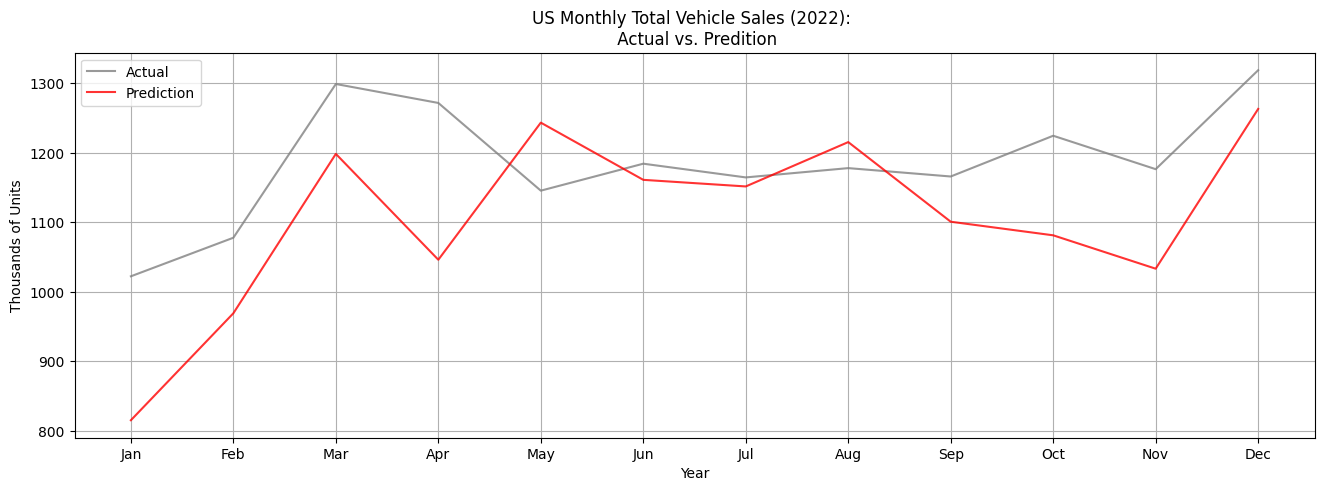

In [34]:
#Actual vs. Prediction
plt.figure(figsize = (16, 5))
plt.plot(test['sales'], 
         color = 'grey', alpha = 0.8, label = 'Actual')
plt.plot(pred_es_fw, 
         color = 'red', alpha = 0.8, label = 'Prediction')
plt.title('US Monthly Total Vehicle Sales (2022): \n Actual vs. Predition')
plt.xlabel('Year')
plt.ylabel('Thousands of Units')
plt.xticks(ticks = test.index , 
           labels = test['month'].unique())
plt.legend()
plt.grid()
plt.show()

## Exponential Smoothing with Expanding Window

In [35]:
test.index

RangeIndex(start=539, stop=551, step=1)

In [36]:
#Expanding window
history = list(train['sales'])
pred_es_ew = []
for t in test.index:
    es = ExponentialSmoothing(history, 
                              trend = 'add', #'add', 'mul', or None
                              damped_trend = False, #    Should the trend component be damped
                              seasonal = 'add', #'add', 'mul', or None
                              seasonal_periods = 12, #The number of periods in a complete seasonal cycle
                              initialization_method = 'estimated', #Method for initialize the recursions
                              initial_level = None, #The initial level component
                              initial_trend = None, #The initial trend component
                              initial_seasonal = None) #The initial seasonal component
    model_2 = es.fit()
    pred_es_ew.append(model_2.forecast(steps = 1)[0])
    history.append(test.loc[t, 'sales'])

In [37]:
#Check the results
pred_es_ew = pd.Series(pred_es_ew, index = test.index)
pred_es_ew

539     815.147140
540    1055.931059
541    1295.152202
542    1145.612639
543    1394.522467
544    1211.117420
545    1189.857050
546    1243.822968
547    1099.812647
548    1107.804078
549    1108.512781
550    1362.020397
dtype: float64

In [38]:
#Absolute error
abs_err_es_ew = abs(test['sales'] - pred_es_ew)
abs_pct_err_es_ew = np.round(abs(test['sales'] - pred_es_ew) / test['sales'] * 100, 1)

#MAPE, MAE, and median, sd, IQR, max, min of absolute errors
from scipy.stats import iqr
models_comp =  pd.concat([models_comp,
                          pd.DataFrame({'MAPE': abs_pct_err_es_ew.mean(),
                                        'MAE':    abs_err_es_ew.mean(),
                                        'Median of AbsErrors' : abs_err_es_ew.median(),
                                        'SD of AbsErrors' :     abs_err_es_ew.std(),
                                        'IQR of AbsErrors':     iqr(abs_err_es_ew),
                                        'Min of AbsErrors':     abs_err_es_ew.min(),
                                        'Max of AbsErrors':     abs_err_es_ew.max()},
                                       index = ['Exponential Smoothing - Expanding Window'])])
models_comp

,MAPE,MAE,Median of AbsErrors,SD of AbsErrors,IQR of AbsErrors,Min of AbsErrors,Max of AbsErrors
Exponential Smoothing - Fixed Window,8.691667,101.777154,99.248646,68.515241,92.120642,12.994810,225.727276
Exponential Smoothing - Expanding Window,7.383333,85.004646,65.979661,76.753978,92.923205,4.012798,248.899467


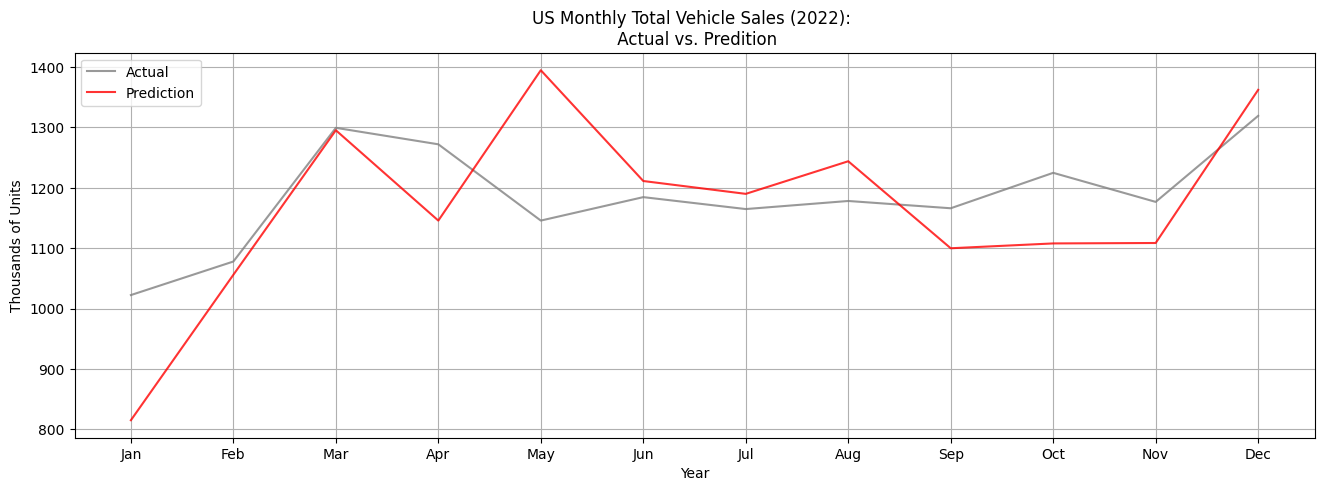

In [39]:
#Actual vs. Prediction
plt.figure(figsize = (16, 5))
plt.plot(test['sales'], 
         color = 'grey', alpha = 0.8, label = 'Actual')
plt.plot(pred_es_ew, 
         color = 'red', alpha = 0.8, label = 'Prediction')
plt.title('US Monthly Total Vehicle Sales (2022): \n Actual vs. Predition')
plt.xlabel('Year')
plt.ylabel('Thousands of Units')
plt.xticks(ticks = test.index , 
           labels = test['month'].unique())
plt.legend()
plt.grid()
plt.show()

## Feature Selection Using RFECV with Expanding Window

In [40]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 539 entries, 0 to 538
Data columns (total 21 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   date    539 non-null    object 
 1   sales   539 non-null    float64
 2   year    539 non-null    int64  
 3   month   539 non-null    object 
 4   trend   539 non-null    int64  
 5   feb     539 non-null    bool   
 6   mar     539 non-null    bool   
 7   apr     539 non-null    bool   
 8   may     539 non-null    bool   
 9   jun     539 non-null    bool   
 10  jul     539 non-null    bool   
 11  aug     539 non-null    bool   
 12  sep     539 non-null    bool   
 13  oct     539 non-null    bool   
 14  nov     539 non-null    bool   
 15  dec     539 non-null    bool   
 16  lag_1   539 non-null    float64
 17  lag_2   539 non-null    float64
 18  lag_9   539 non-null    float64
 19  lag_12  539 non-null    float64
 20  lag_13  539 non-null    float64
dtypes: bool(11), float64(6), int64(2), obje

In [41]:
#Define feature matrix for train
X_train = train.iloc[:, 4:]
X_train

,trend,feb,mar,apr,may,jun,jul,aug,sep,oct,nov,dec,lag_1,lag_2,lag_9,lag_12,lag_13
0,14,True,False,False,False,False,False,False,False,False,False,False,969.900,1061.800,1203.200,994.700,885.200
1,15,False,True,False,False,False,False,False,False,False,False,False,1092.100,969.900,1254.700,1243.600,994.700
2,16,False,False,True,False,False,False,False,False,False,False,False,1451.100,1092.100,1162.300,1191.200,1243.600
3,17,False,False,False,True,False,False,False,False,False,False,False,1354.400,1451.100,1026.100,1203.200,1191.200
4,18,False,False,False,False,True,False,False,False,False,False,False,1377.100,1354.400,1057.900,1254.700,1203.200
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
534,548,False,False,False,False,False,False,True,False,False,False,False,1316.697,1342.999,1235.258,1354.397,1268.455
535,549,False,False,False,False,False,False,False,True,False,False,False,1128.965,1316.697,1651.406,1379.676,1354.397
536,550,False,False,False,False,False,False,False,False,True,False,False,1052.965,1128.965,1141.709,1399.305,1379.676
537,551,False,False,False,False,False,False,False,False,False,True,False,1089.348,1052.965,1226.714,1235.258,1399.305


In [42]:
#Scale data
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

In [43]:
#Define response matrix for train
y_train = train['sales']
y_train

0      1092.100
1      1451.100
2      1354.400
3      1377.100
4      1459.800
         ...   
534    1128.965
535    1052.965
536    1089.348
537    1049.604
538    1250.985
Name: sales, Length: 539, dtype: float64

In [44]:
#Define the splits for RFECV
val_period = 5 * 12 #last 5 years
idn = np.arange(len(X_train_scaled))
cv_splits = [(idn[: i], idn[i : i + 1]) for i in range(len(X_train_scaled) - val_period, len(X_train_scaled))]
cv_splits

[(array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
          13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
          26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
          39,  40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,
          52,  53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,
          65,  66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,
          78,  79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,
          91,  92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103,
         104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116,
         117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129,
         130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142,
         143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155,
         156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168,
         169, 170, 171, 172, 173, 174,